# Panama elektrikoormuse uuriv andmeanalüüs

Uuriva andmeanalüüsi eesmärk on kirjeldada Panama tunnipõhise elektrikoormuse muutumist ajas ning uurida, kuidas koormus seostub ilmastiku- ja kalendritunnustega. Analüüs aitab teha põhjendatud valikuid järgneva prognoosimudeli lähteülesandes, kuid **ei asenda mudelite võrdlust ega tõenda põhjuslikke seoseid**.

Andmed jagatakse kronoloogiliselt treeningperioodiks (enne 2018. aastat), valideerimisperioodiks (2018–2019) ja testperioodiks (alates 2020. aastast). Kirjeldavad seosed, mille põhjal võidakse hiljem valida mudeli tunnuseid, arvutatakse ainult treeningandmetest. Kogu aegrea ülevaadet ja valideerimisperioodi üksikjuhtumeid kasutatakse siin andmete kvaliteedi hindamiseks, mitte mudeli kohandamiseks.

Notebook kasutab faili `eda_lihtsustatud.py` funktsioone. Kõik üheksa joonist salvestatakse PNG-failidena; täiendavaid vahepealseid CSV- või JSON-aruandeid ei koostata. Tabelid ja põhinäitajad kuvatakse otse siin.

## 1. Andmete laadimine

Andmestik loetakse sisse sama funktsiooniga, mida kasutab eraldiseisev analüüsiskript. Nii ei teki olukorda, kus notebook ja `.py` fail töötlevad sisendandmeid erinevalt. Alguses kuvatakse mõned esimesed read, et kontrollida ajatemplite ja tunnuste olemasolu.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import Image, display

project_root = Path.cwd().resolve()

if project_root.name == "notebooks":
    project_root = project_root.parent

sys.path.insert(0, str(project_root))

from src.eda import load_and_validate, split_periods, run_eda

input_path = project_root / "data/raw/continuous dataset.csv"

if not input_path.exists():
    raise FileNotFoundError(f"Andmefaili ei leitud: {input_path}")

data, quality = load_and_validate(input_path)
splits = split_periods(data)

train = splits["train"]
validation = splits["validation"]
test = splits["test"]

print(f"Kasutatav andmefail: {input_path.name}")
print(f"Andmestikus on {len(data):,} vaatlust.")

display(data.head())

Kasutatav andmefail: continuous dataset.csv
Andmestikus on 48,048 vaatlust.


,datetime,nat_demand,T2M_toc,QV2M_toc,TQL_toc,W2M_toc,T2M_san,QV2M_san,TQL_san,W2M_san,T2M_dav,QV2M_dav,TQL_dav,W2M_dav,Holiday_ID,holiday,school
0,2015-01-03 01:00:00,970.3450,25.865259,0.018576,0.016174,21.850546,23.482446,0.017272,0.001855,10.328949,22.662134,0.016562,0.096100,5.364148,0,0,0
1,2015-01-03 02:00:00,912.1755,25.899255,0.018653,0.016418,22.166944,23.399255,0.017265,0.001327,10.681517,22.578943,0.016509,0.087646,5.572471,0,0,0
2,2015-01-03 03:00:00,900.2688,25.937280,0.018768,0.015480,22.454911,23.343530,0.017211,0.001428,10.874924,22.531030,0.016479,0.078735,5.871184,0,0,0
3,2015-01-03 04:00:00,889.9538,25.957544,0.018890,0.016273,22.110481,23.238794,0.017128,0.002599,10.518620,22.512231,0.016487,0.068390,5.883621,0,0,0
4,2015-01-03 05:00:00,893.6865,25.973840,0.018981,0.017281,21.186089,23.075403,0.017059,0.001729,9.733589,22.481653,0.016456,0.064362,5.611724,0,0,0


## 2. Andmete kvaliteet ja analüüsiperioodid

Elektrikoormuse aegrea korral on oluline, et ajatempleid ei esineks korduvalt, tunnid oleksid järjestikused ning koormusel puuduksid puuduvaid või mittepositiivseid väärtusi sisaldavad vaatlused. Vastasel korral võivad näiteks tunnimuutused ja autokorrelatsioonid anda eksitava tulemuse. Seetõttu peatab `.py` fail analüüsi, kui mõni neist kriitilistest kontrollidest ebaõnnestub.

Lisaks kuvatakse kontrollid, mis ei lõpeta automaatselt analüüsi, näiteks pühatunnuste võimalik vastuolu. Need vajavad vajaduse korral eraldi sisulist ülevaatust. Perioodide tabel teeb nähtavaks, millisele ajavahemikule edasised järeldused tuginevad.

In [2]:
checks = {
    'Vaatluste arv': quality['rows'],
    'Tunnuste arv': quality['columns'],
    'Puuduvad väärtused': quality['missing_cells'],
    'Korduvad ajatemplid': quality['duplicate_timestamps'],
    'Ebaregulaarsed tunniintervallid': quality['non_hourly_intervals'],
    'Mittepositiivne koormus': quality['nonpositive_load'],
    'Pühatunnuste vastuolud': quality['holiday_id_disagreement'],
    'Esimene ajatempel': quality['first_timestamp'],
    'Viimane ajatempel': quality['last_timestamp'],
}
display(pd.Series(checks, name='Tulemus').to_frame())

periods = pd.DataFrame([
    {'Periood': {'train': 'Treening', 'validation': 'Valideerimine', 'test': 'Test'}[name],
     'Vaatlusi': len(frame), 'Algus': frame.datetime.min(),
     'Lõpp': frame.datetime.max(), 'Keskmine koormus': frame.nat_demand.mean()}
    for name, frame in splits.items()
])
display(periods.round({
    col: 2 for col in periods.select_dtypes(include="number").columns
}))

,Tulemus
Vaatluste arv,48048
Tunnuste arv,17
Puuduvad väärtused,0
Korduvad ajatemplid,0
Ebaregulaarsed tunniintervallid,0
Mittepositiivne koormus,0
Pühatunnuste vastuolud,0
Esimene ajatempel,2015-01-03 01:00:00
Viimane ajatempel,2020-06-27 00:00:00


,Periood,Vaatlusi,Algus,Lõpp,Keskmine koormus
0,Treening,26255,2015-01-03 01:00:00,2017-12-31 23:00:00,1157.06
1,Valideerimine,17520,2018-01-01 00:00:00,2019-12-31 23:00:00,1224.63
2,Test,4273,2020-01-01 00:00:00,2020-06-27 00:00:00,1170.23


**Tõlgendamine.** Null puuduvate väärtuste, korduvate ajatemplite ja ebaregulaarsete intervallide real tähendab, et aegrida läbis vastavad tehnilised kontrollid. See ei välista siiski üksikuid valesid mõõtmisi ega selgita ebatavaliste väärtuste põhjusi. Edasine seoseanalüüs põhineb ainult treeningperioodil, et hilisemate perioodide teave ei mõjutaks prognoosimudeli väljatöötamist.

## 3. Jooniste koostamine

Joonised arvutatakse `eda.py` abil. Nii on visualiseerimiste arvutused ühes kohas ning notebook keskendub tulemuste esitamisele ja tõlgendamisele. Pildifailide nimetused jäävad samaks nagu Pythoni skriptis.

In [3]:
run_eda(input_path, project_root / 'results')
figures_dir = project_root / 'results/figures/eda'

def show_figure(filename, caption):
    print(caption)
    display(Image(filename=str(figures_dir / filename), width=850))

Analüüs valmis. Andmeridu: 48048
Treeningandmeid: 26255, valideerimisandmeid: 17520, testandmeid: 4273
Koormuse autokorrelatsioon (1 tund): 0.949
Koormuse ja temperatuuri korrelatsioon: 0.687
Graafikud salvestati kausta: C:\Users\danyi\Desktop\TALTECH magister\Magistritöö\xai\results\figures\eda


## 4. Koormuse ajalised mustrid

Joonis 1 annab ülevaate kogu andmestiku ööpäevastest keskmistest ning toob eraldi välja ühe järsu muutusega perioodi 2017. aastal. Kogu perioodi kuvamine aitab märgata andmete võimalikke katkestusi ja struktuurseid muutusi; see ei ole hilisema mudeli tunnuste valiku alus. Joonis 2 võrdleb koormuse keskmist tunniprofiili tööpäevadel ja nädalavahetustel ning nädalapäevade lõikes. Joonis 9 näitab kuude keskmisi ja võimaldab võrrelda, kas sarnane hooajaline muster kordub eri treeningaastatel.

Need võrdlused on vajalikud, sest elektritarbimine võib sõltuda inimeste igapäevasest tegevusrütmist ja aastaajast. Kui erinevused on järjepidevad, võivad kellaaeg, nädalapäev ja kuu olla prognoosimisel mõistlikud kandidaattunnused.

Joonis 1. Elektrikoormuse aegrida ja 2017. aasta erandlik periood


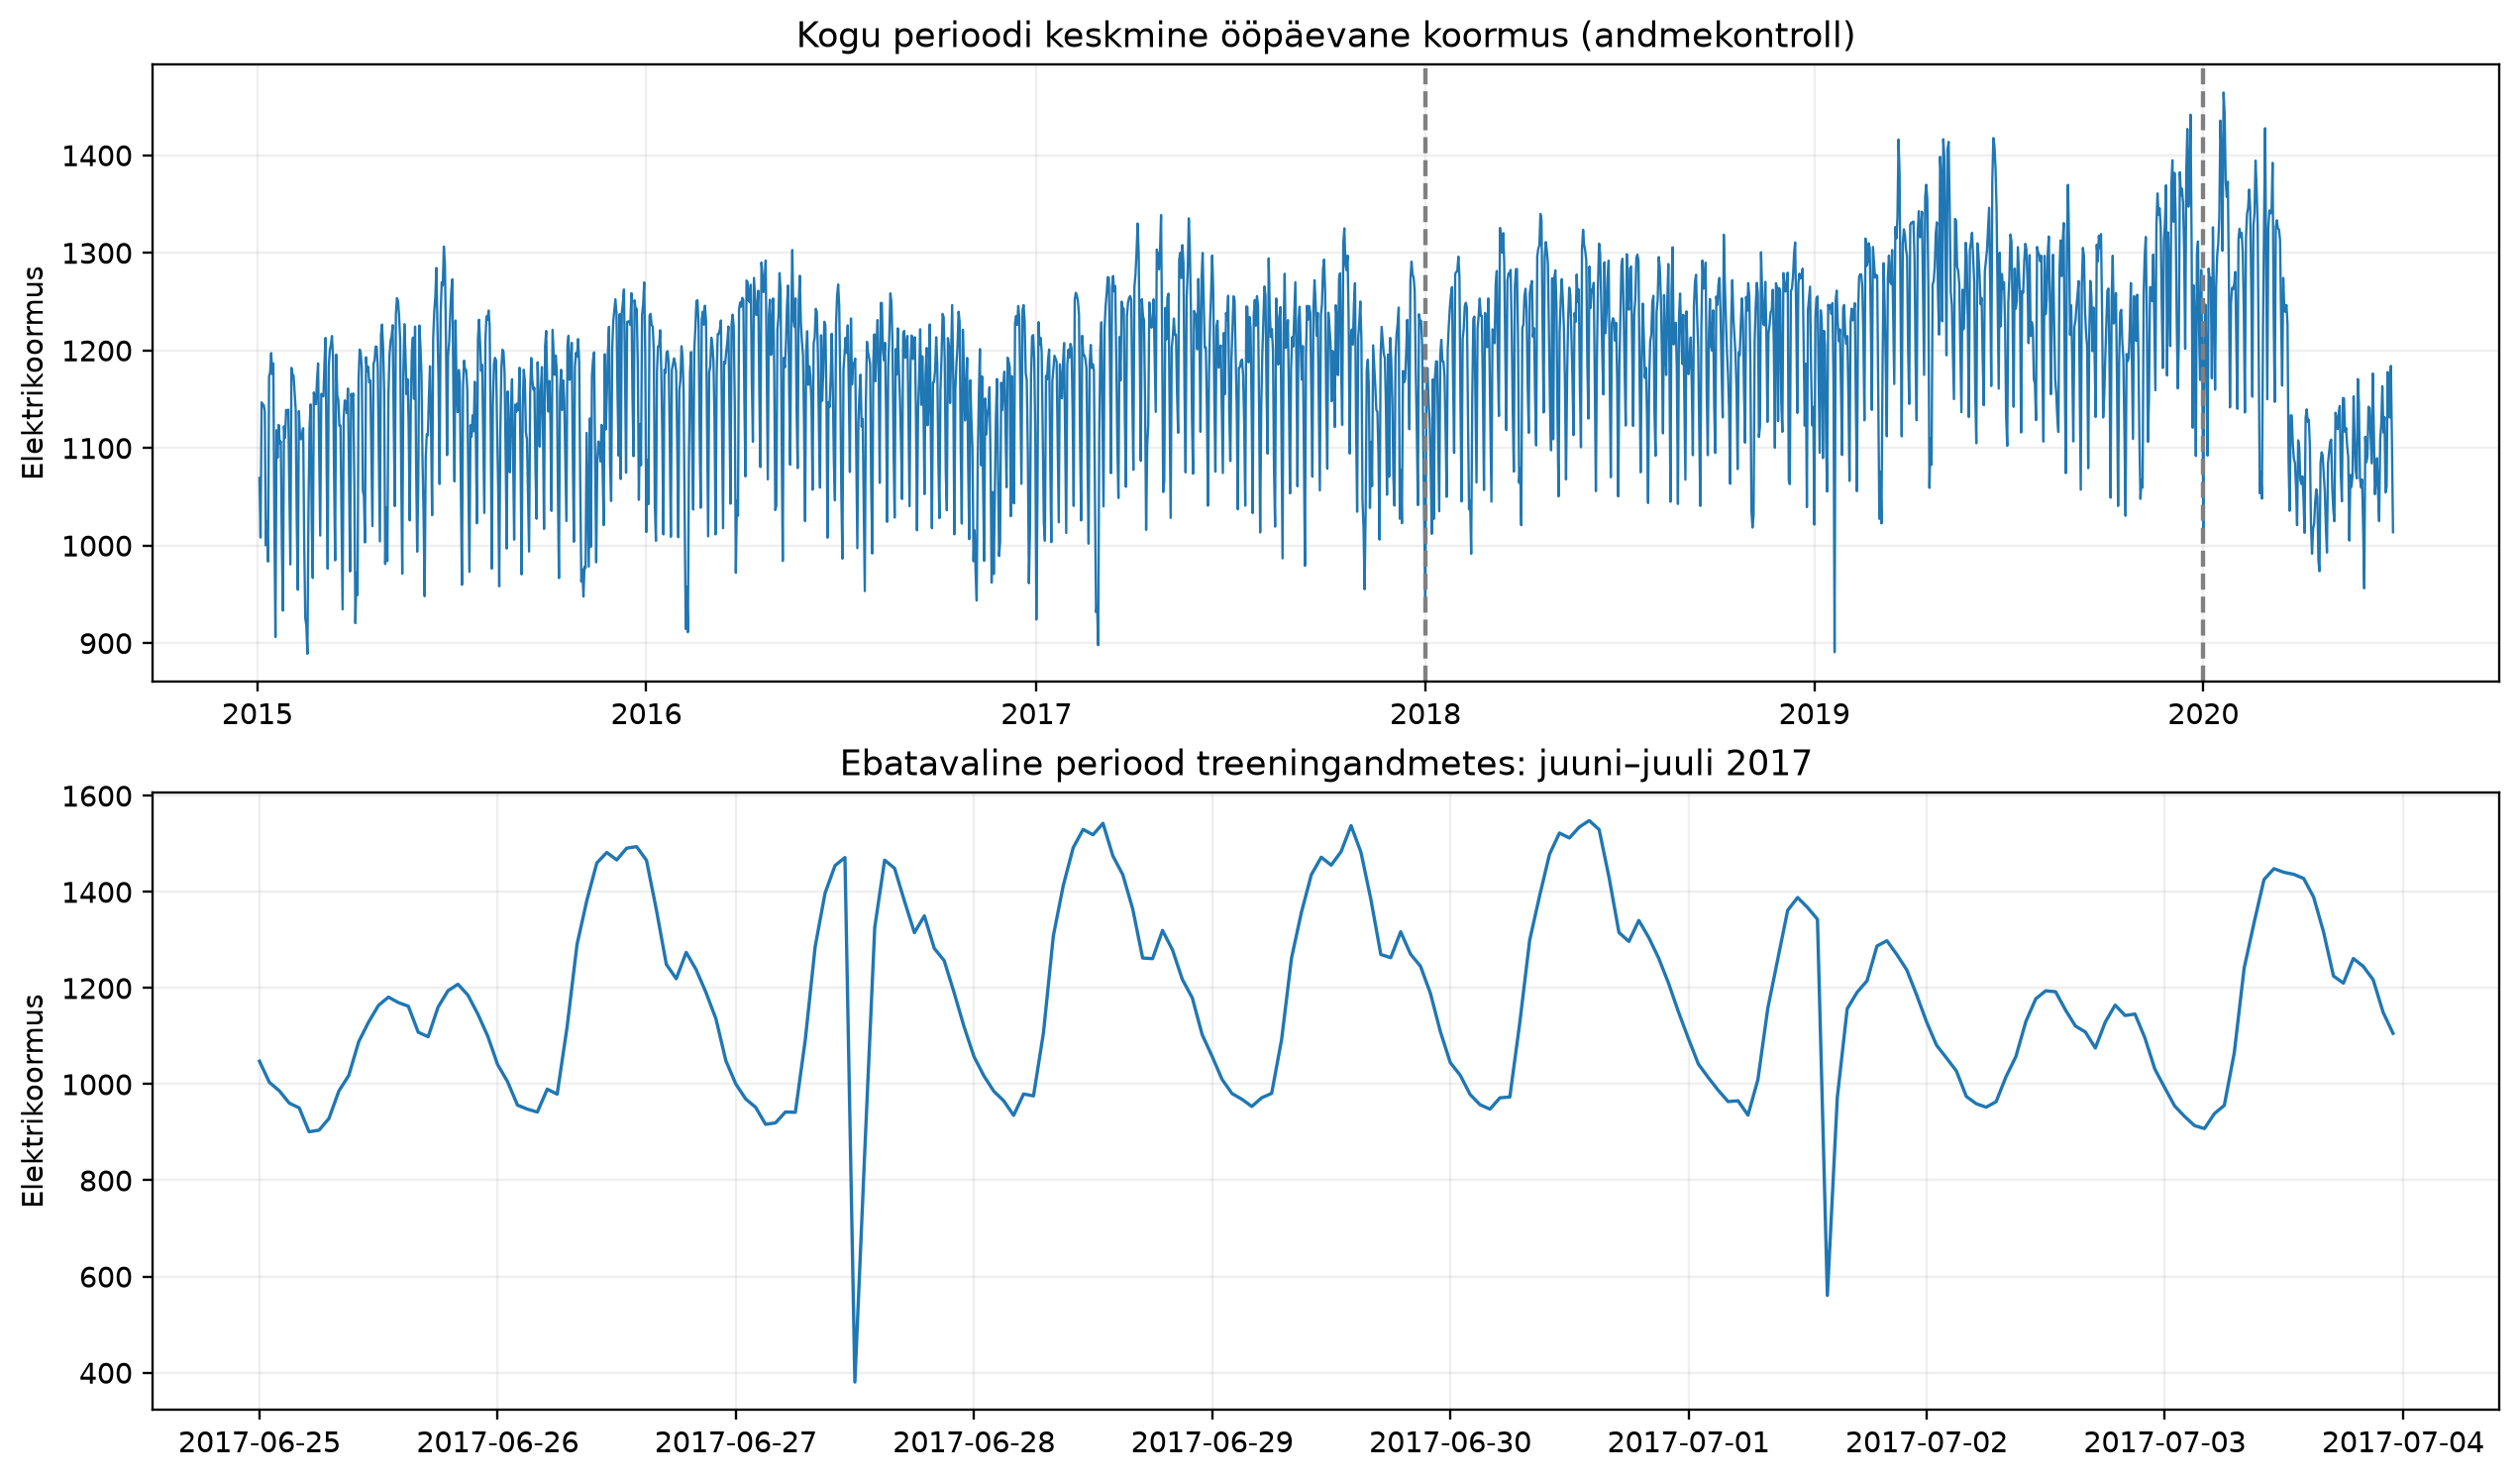

Joonis 2. Keskmine koormus kellaaja ja nädalapäeva järgi


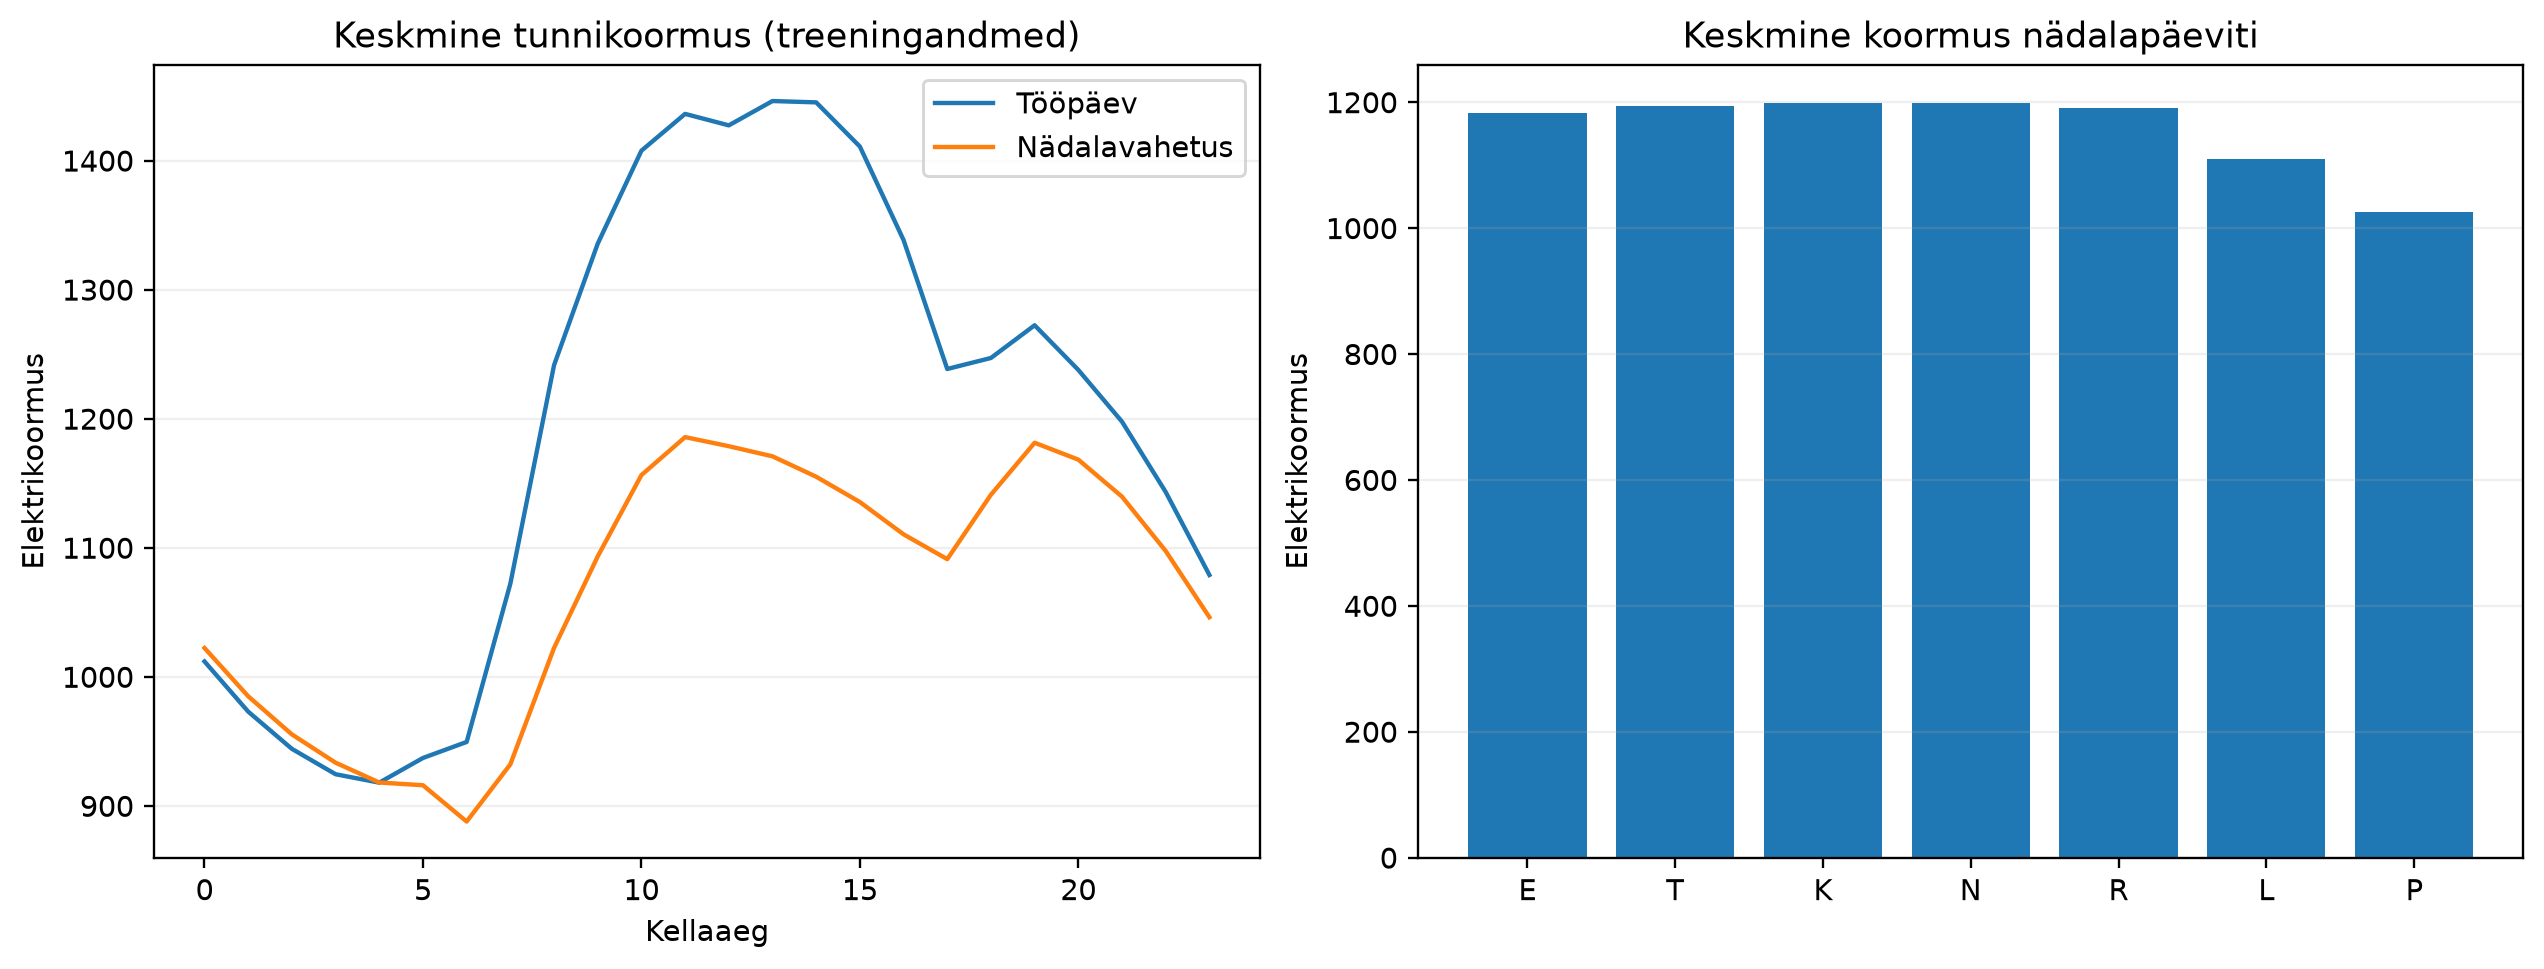

Joonis 9. Keskmine koormus kalendrikuude järgi


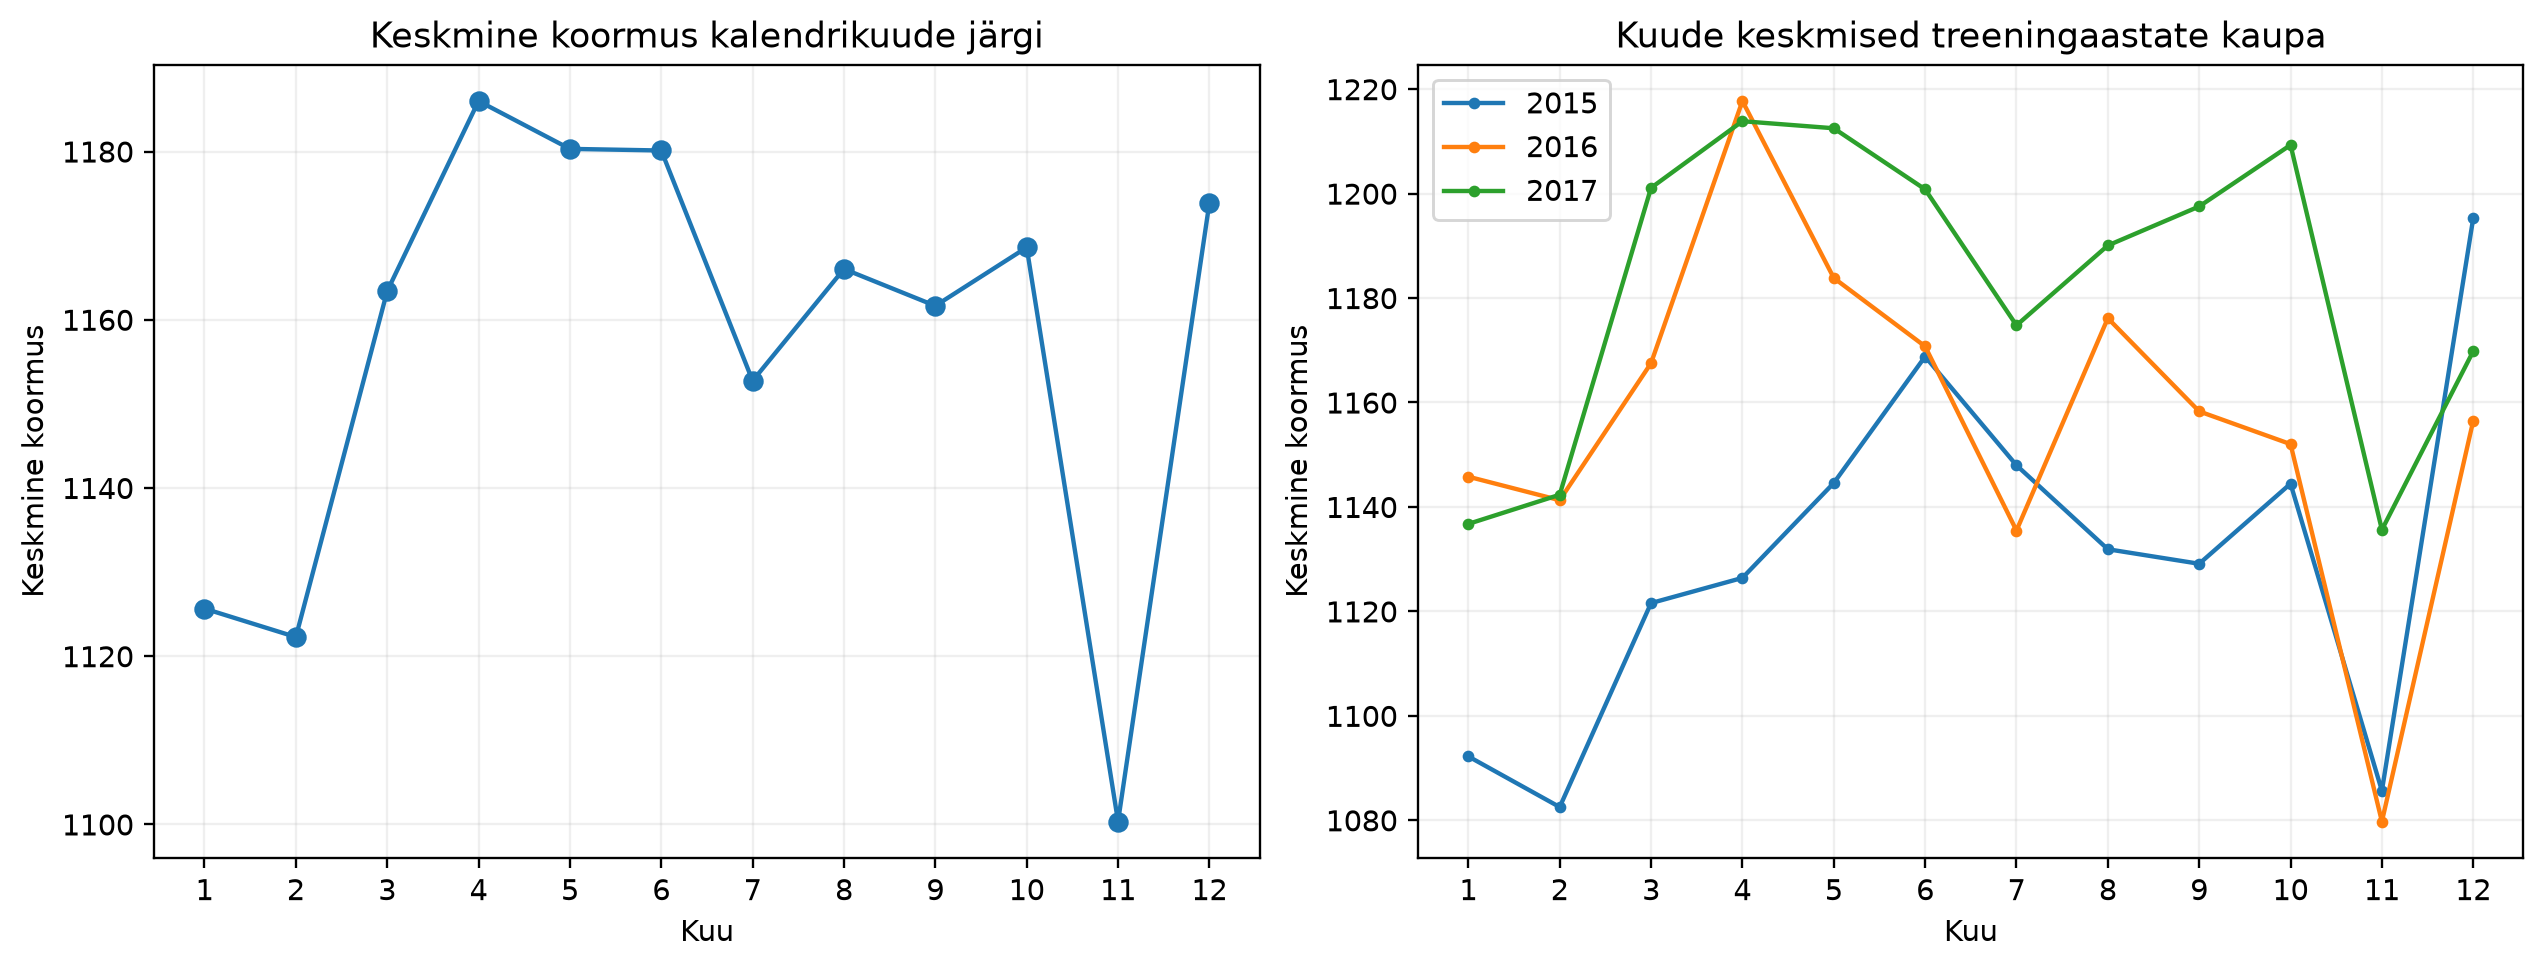

Suurima keskmise koormusega tund: 13:00 (1367.09)
Väikseima keskmise koormusega tund: 04:00 (917.98)
Tunniprofiili maksimumi ja miinimumi vahe: 449.11
Suurima keskmise koormusega kuu: 4 (1186.00)
Väikseima keskmise koormusega kuu: 11 (1100.34)
Nädalapäevade keskmiste vahemik: 173.75


In [4]:
show_figure('01_load_timeseries.png', 'Joonis 1. Elektrikoormuse aegrida ja 2017. aasta erandlik periood')
show_figure('02_load_patterns.png', 'Joonis 2. Keskmine koormus kellaaja ja nädalapäeva järgi')
show_figure('09_monthly_profiles.png', 'Joonis 9. Keskmine koormus kalendrikuude järgi')

hourly = train.groupby(train.datetime.dt.hour).nat_demand.mean()
monthly = train.groupby(train.datetime.dt.month).nat_demand.mean()
weekday = train.groupby(train.datetime.dt.dayofweek).nat_demand.mean()
print(f'Suurima keskmise koormusega tund: {hourly.idxmax():02d}:00 ({hourly.max():.2f})')
print(f'Väikseima keskmise koormusega tund: {hourly.idxmin():02d}:00 ({hourly.min():.2f})')
print(f'Tunniprofiili maksimumi ja miinimumi vahe: {hourly.max() - hourly.min():.2f}')
print(f'Suurima keskmise koormusega kuu: {monthly.idxmax()} ({monthly.max():.2f})')
print(f'Väikseima keskmise koormusega kuu: {monthly.idxmin()} ({monthly.min():.2f})')
print(f'Nädalapäevade keskmiste vahemik: {weekday.max() - weekday.min():.2f}')

**Tulemuse tõlgendamine.** Eelmise lahtri arvud näitavad, millal esineb treeningperioodil keskmiselt suurim ja väikseim koormus ning kui suur on nende erinevus. Tunniprofiili amplituud kirjeldab tüüpilise päeva sisest muutlikkust, kuid ei näita iga üksiku päeva käitumist. Kuude võrdlus aitab hinnata võimalikku sesoonsust; samas võivad eri aastate temperatuurid ja muud tingimused kuukeskmisi mõjutada. Joonisel 1 esinevaid järske muutusi ei tohi üksnes visuaalse mulje põhjal vigadeks lugeda.

## 5. Temperatuuri ja koormuse seos

Joonisel 3 kasutatakse kahte vaadet. Tihedusgraafik näitab, millistes temperatuuri ja koormuse kombinatsioonides on vaatlusi rohkem. Temperatuurivahemike keskmised eristavad päevaseid (09–18) ja öiseid (00–05) tunde, sest temperatuuriga seotud tarbimismuster võib sõltuda kellaajast. Joonis 7 kujutab Pearsoni korrelatsioonikordajaid: see aitab leida tugevaid lineaarseid seoseid nii sihtmuutuja kui ka võimalike selgitavate tunnuste vahel.

Korrelatsioonide uurimine on vajalik enne modelleerimist, et märgata võimalikke kattuva teabega ilmastikutunnuseid. Pearsoni korrelatsioon ei kirjelda aga hästi mittelineaarseid seoseid; seetõttu tuleb tõlgendada seda koos temperatuurigraafikuga.

Joonis 3. Temperatuuri ja elektrikoormuse seos


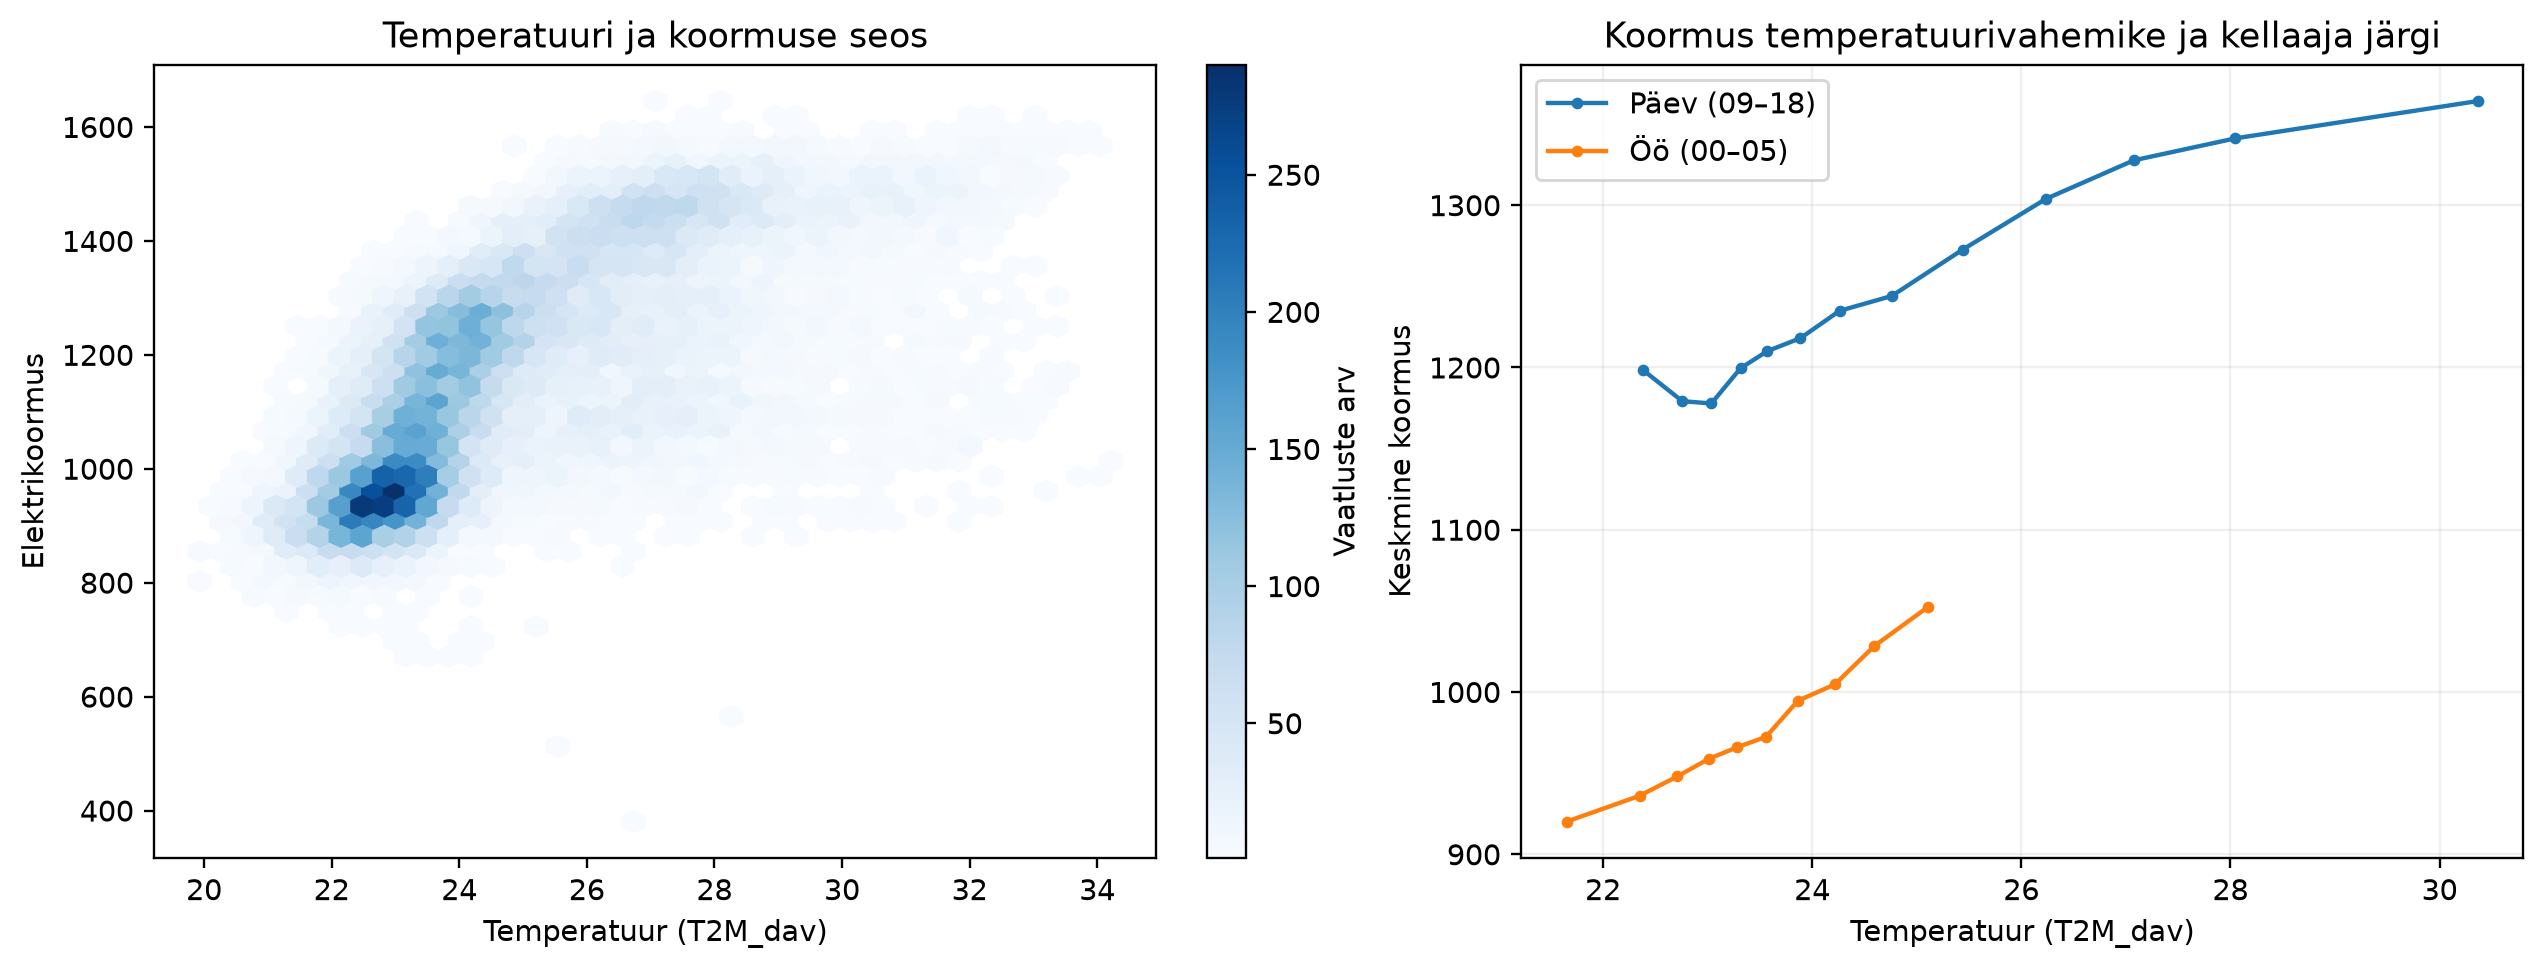

Joonis 7. Treeningandmete korrelatsioonimaatriks


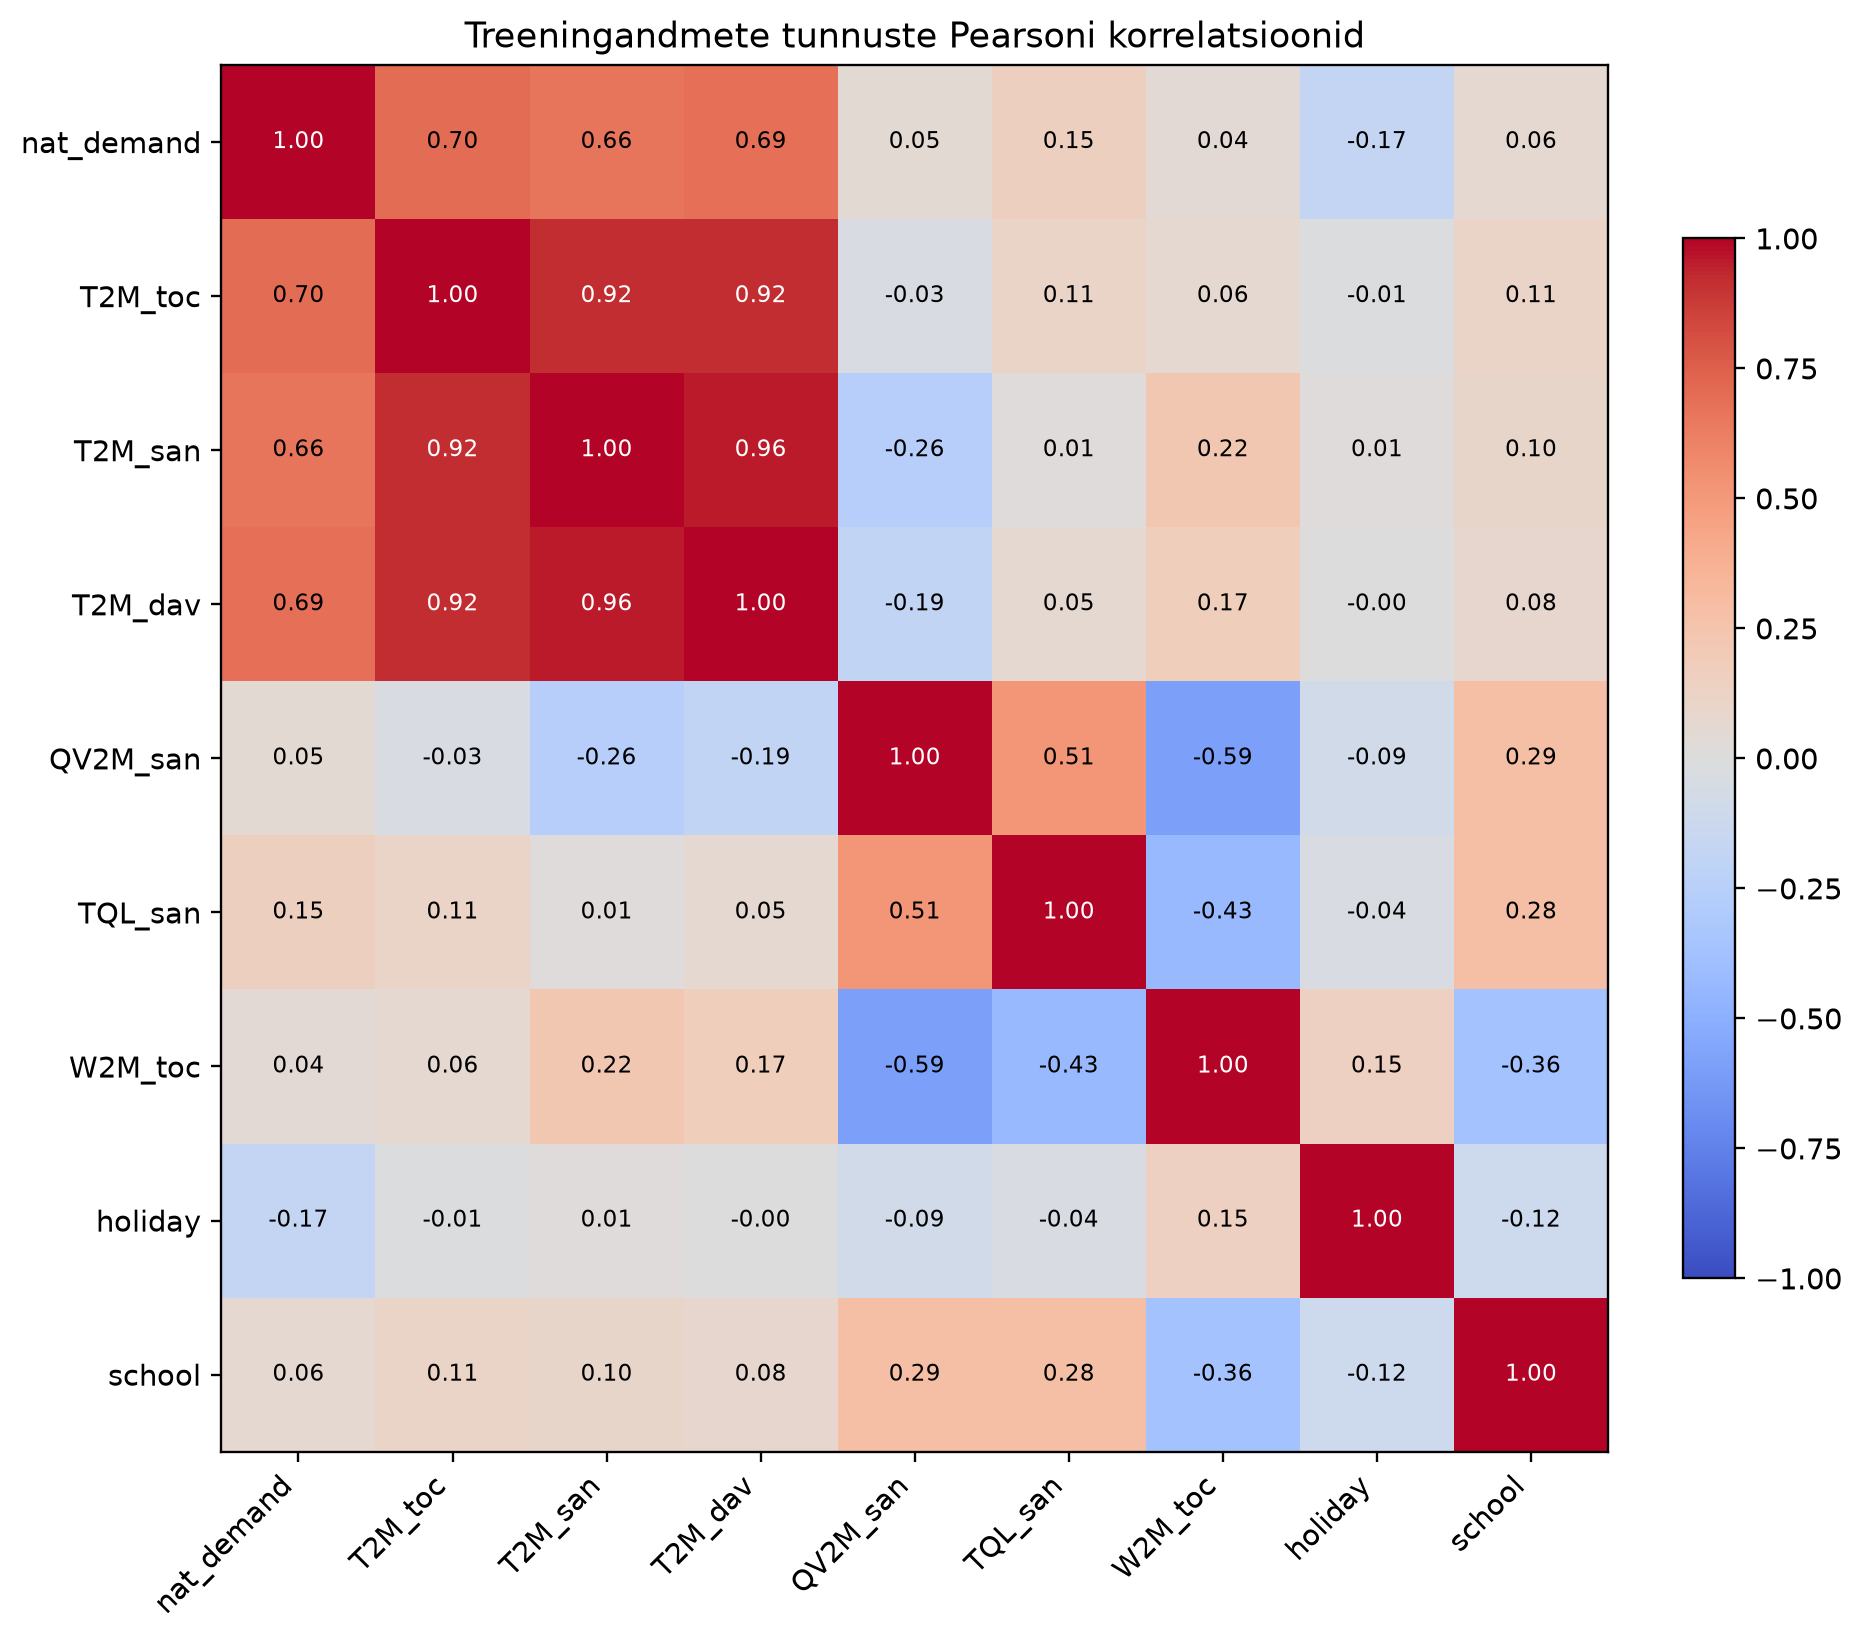

Koormuse ja T2M_dav temperatuuri Pearsoni r: 0.687
T2M_san ja T2M_dav temperatuuride Pearsoni r: 0.957


In [5]:
show_figure('03_temperature_demand.png', 'Joonis 3. Temperatuuri ja elektrikoormuse seos')
show_figure('07_correlations.png', 'Joonis 7. Treeningandmete korrelatsioonimaatriks')

load_temp_corr = train.nat_demand.corr(train.T2M_dav)
weather_corr = train.T2M_san.corr(train.T2M_dav)
print(f'Koormuse ja T2M_dav temperatuuri Pearsoni r: {load_temp_corr:.3f}')
print(f'T2M_san ja T2M_dav temperatuuride Pearsoni r: {weather_corr:.3f}')

**Tulemuse tõlgendamine.** Koormuse ja temperatuuri korrelatsiooni märk näitab lineaarse seose suunda, absoluutväärtus selle tugevust treeningandmetes. Nullilähedane kordaja ei välista U-kujulist või muul viisil mittelineaarset sõltuvust. Kahe temperatuuritunnuse tugev omavaheline korrelatsioon viitab sarnasele informatsioonile, kuid ei tähenda, et üks tunnus tuleks tingimata eemaldada. Tunnuste tegelik lisaväärtus tuleb hiljem kindlaks teha valideerimisel. Lisaks tuleb enne prognoosimudeli rakendamist kontrollida, kas kasutatavad ilmatunnused on ennustushetkel teada või on tegu alles hiljem mõõdetud väärtustega.

## 6. Tunnimuutused ja autokorrelatsioon

Koormuse esimene diferents kirjeldab, kui palju elektrikoormus ühe tunni jooksul muutub. Joonis 4 näitab muutuste jaotust ning erinevusi kellaaja lõikes. Histogrammis on keskosa parema nähtavuse huvides jäetud välja mõlema saba kõige äärmisemad 0,5% väärtused; algseid vaatlusi ega järgmisi arvutusi see ei muuda. Joonis 8 näitab autokorrelatsiooni kuni 168-tunnise nihkeni, s.o ühe nädalani.

Autokorrelatsiooniga hinnatakse, kuivõrd sarnaneb koormus oma varasema väärtusega. Eraldi on huvipakkuvad nihked 1, 24 ja 168 tundi: eelmine tund, eelmise päeva sama tund ja eelmise nädala sama tund.

Joonis 4. Elektrikoormuse tunnipõhised muutused


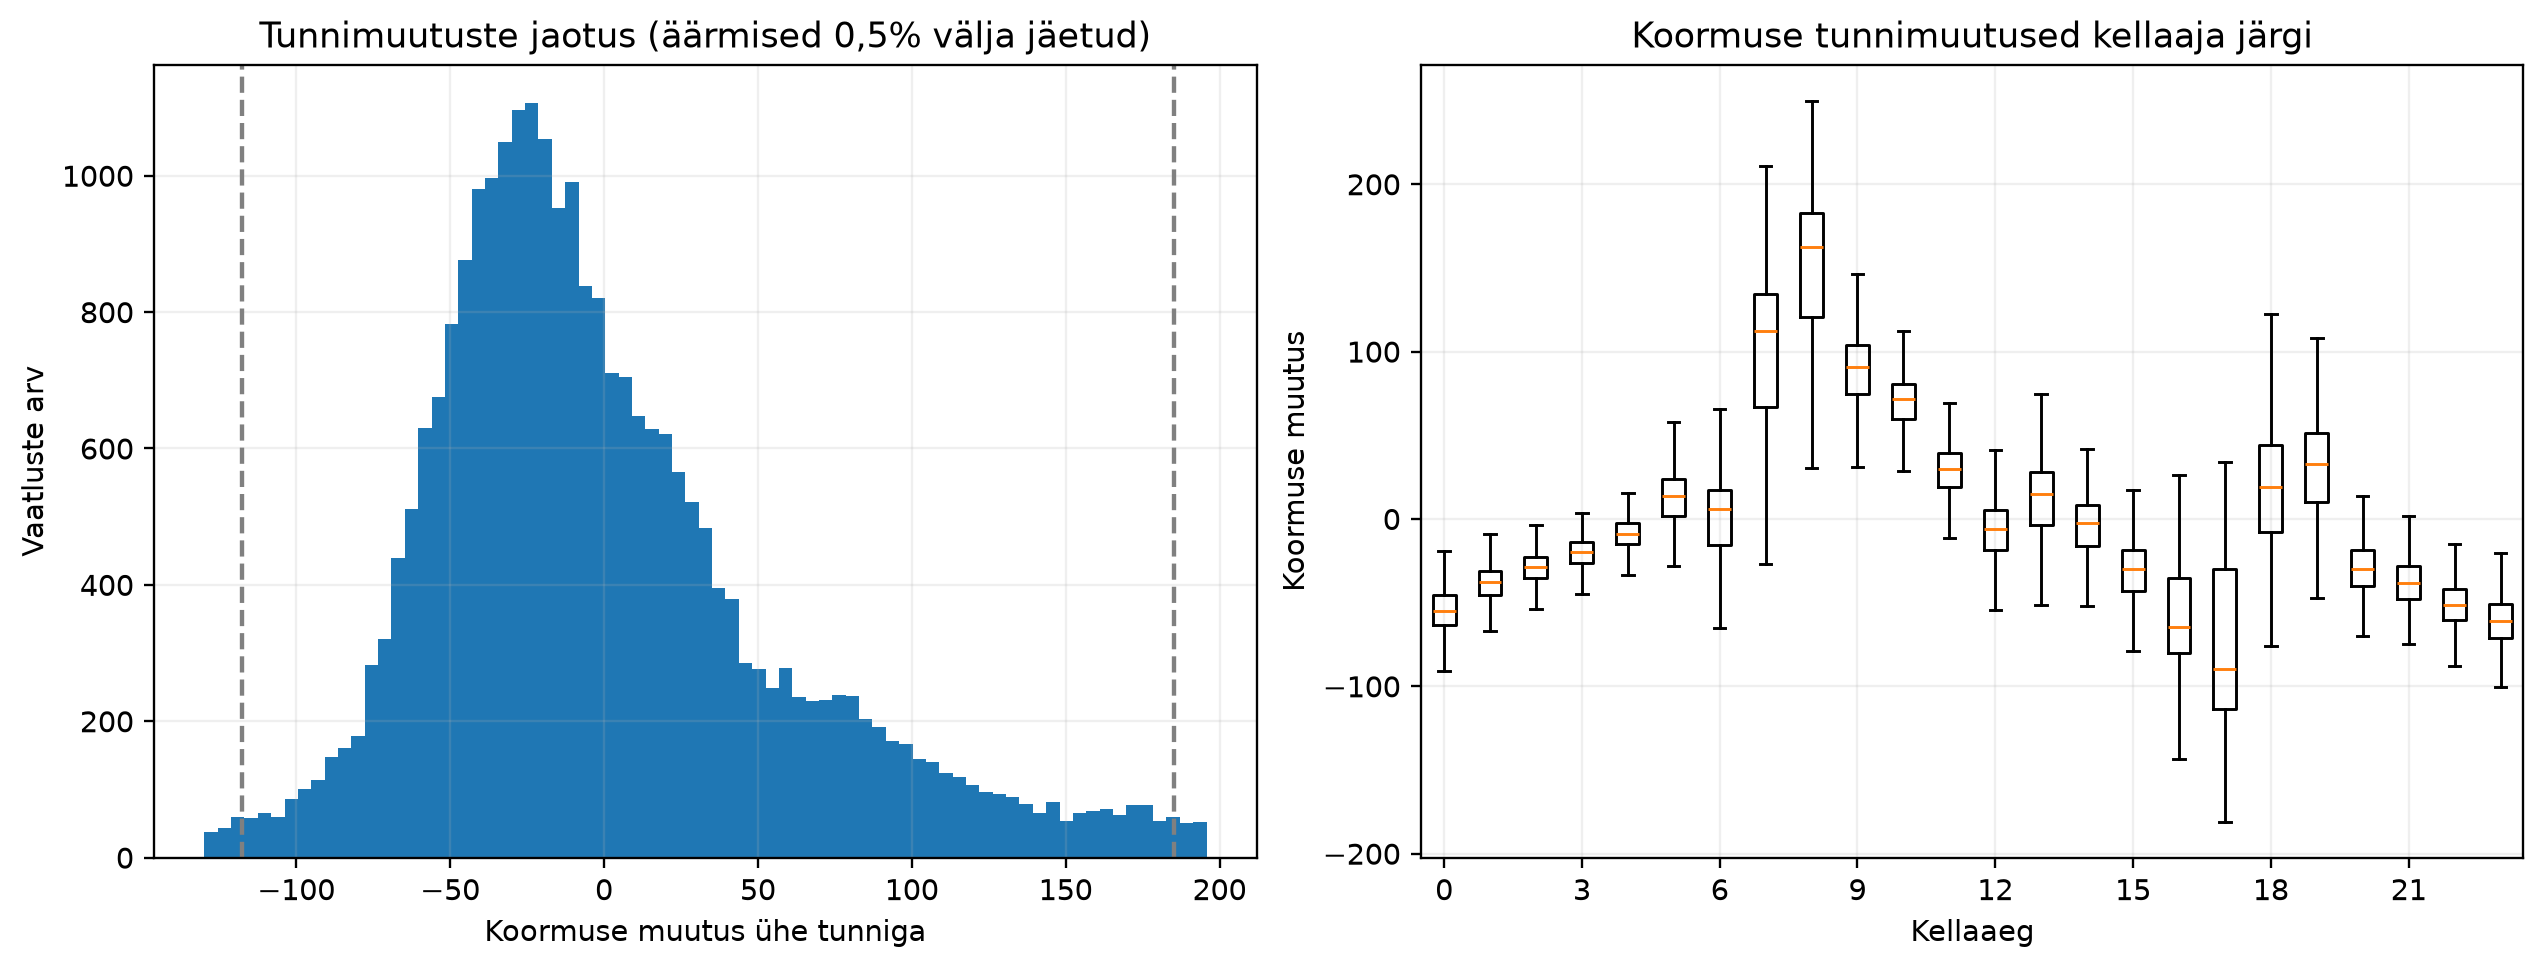

Joonis 8. Elektrikoormuse autokorrelatsioon


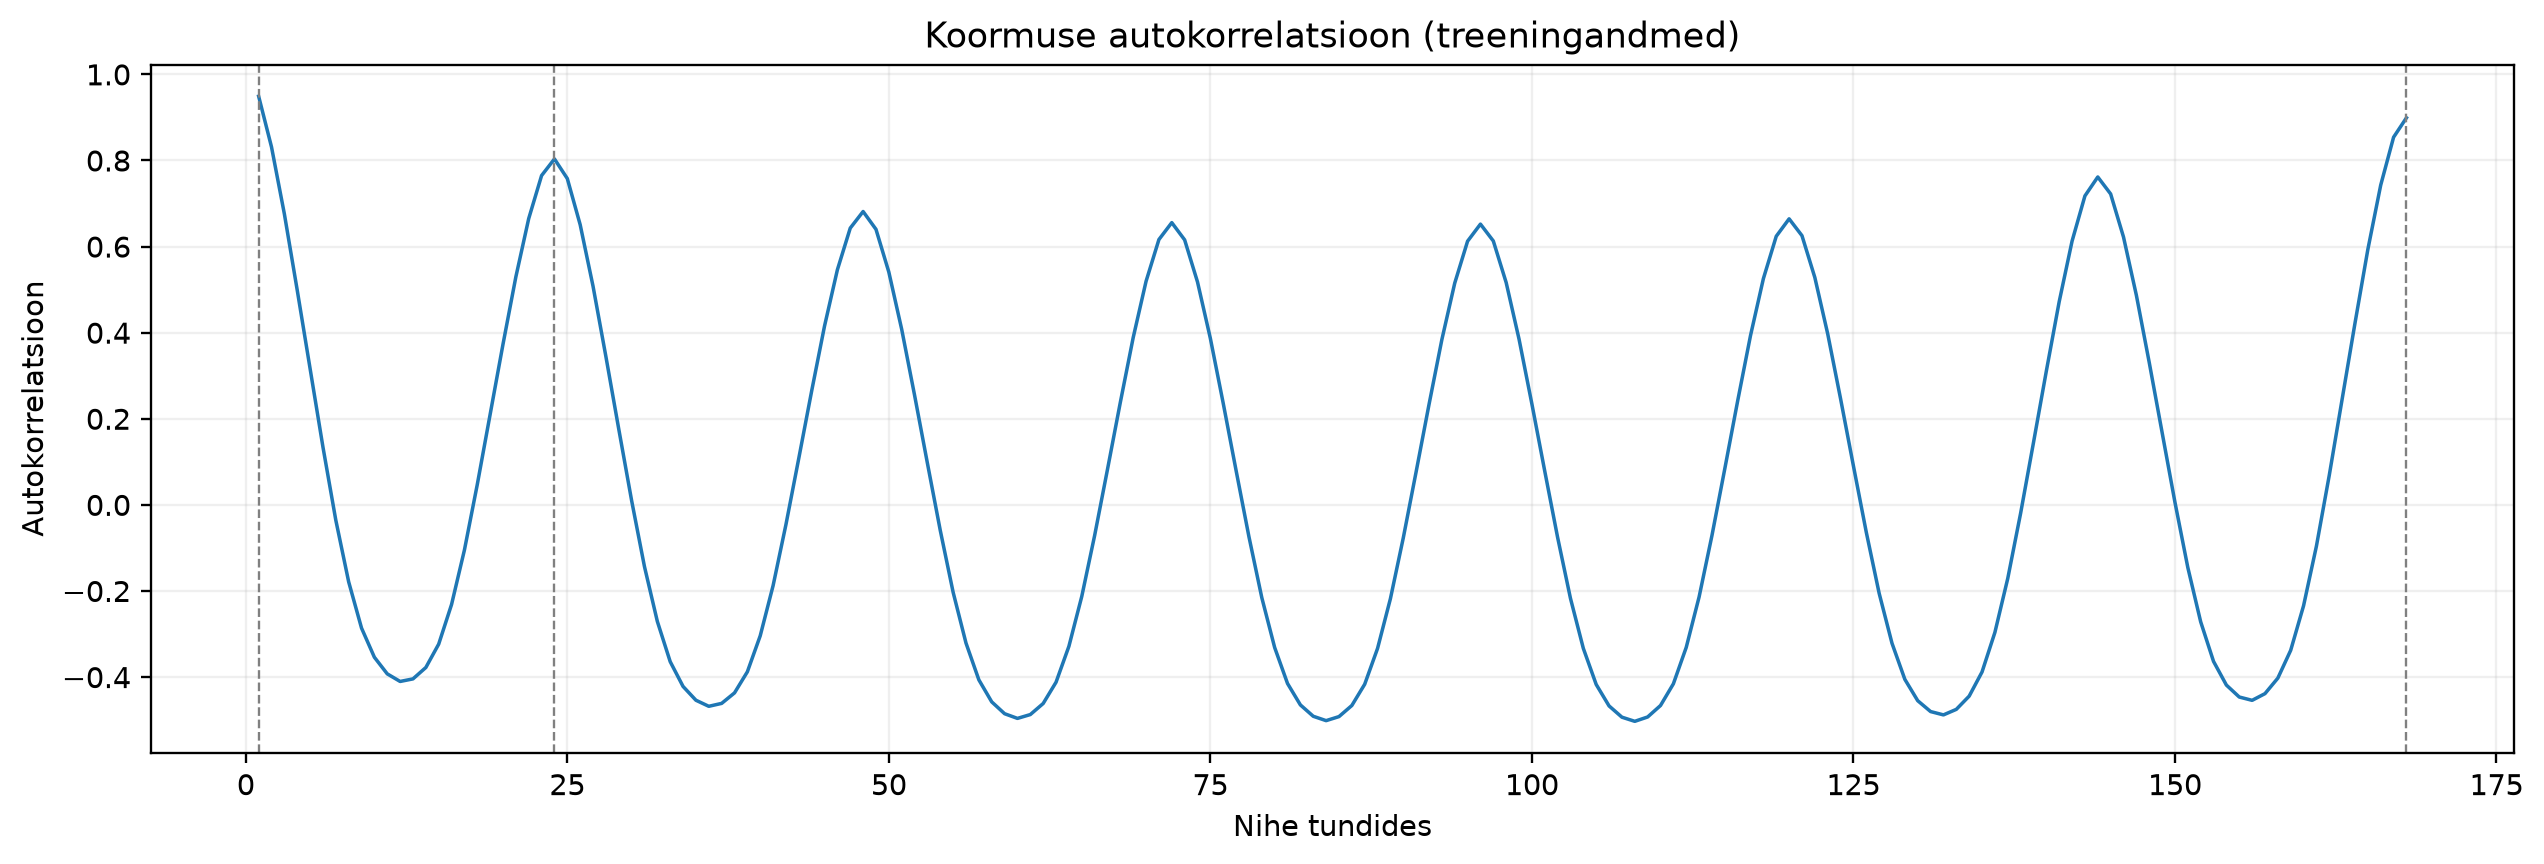

Suurim tunnipõhine kasv: 481.20
Suurim tunnipõhine langus: -1090.70
Tunnimuutuse mediaan: -12.13
Autokorrelatsioon nihkega 1 tundi: 0.949
Autokorrelatsioon nihkega 24 tundi: 0.803
Autokorrelatsioon nihkega 168 tundi: 0.899


In [6]:
show_figure('04_load_changes.png', 'Joonis 4. Elektrikoormuse tunnipõhised muutused')
show_figure('08_autocorrelation.png', 'Joonis 8. Elektrikoormuse autokorrelatsioon')

changes = train.nat_demand.diff().dropna()
print(f'Suurim tunnipõhine kasv: {changes.max():.2f}')
print(f'Suurim tunnipõhine langus: {changes.min():.2f}')
print(f'Tunnimuutuse mediaan: {changes.median():.2f}')
for lag in (1, 24, 168):
    print(f'Autokorrelatsioon nihkega {lag} tundi: {train.nat_demand.autocorr(lag):.3f}')

**Tulemuse tõlgendamine.** Suurim tõus ja langus kirjeldavad erandlikke tunnimuutusi, mediaan aga tüüpilist suunda. Kui autokorrelatsioon on 24 või 168 tunni juures kõrge, toetab see vastavate viitajatunnuste katsetamist. Autokorrelatsioon ei ole siiski prognoositäpsuse mõõdik: tugev seos minevikuga ei tõesta, et mudel üldistab hästi uutele perioodidele. Samuti võivad pikaajaline trend ja sesoonsus autokorrelatsiooni suurendada. Ebatavaliste tunnimuutuste mõju mudelivigadele tuleb hiljem eraldi hinnata.

## 7. Pühad ja võimalikud erandlikud vaatlused

Pühatunnuse analüüsis võrreldakse pühade ja tavapäevade koormuse jaotust ning keskmist tunniprofiili. Joonis 5 annab esialgse hinnangu sellele, kas kalendritunnus võiks olla prognoosimisel kasulik. Kuna puhke- ja tööpäevade koosseis ning aastaajad võivad erineda, on tegemist **korrigeerimata kirjeldava võrdlusega**, mitte püha iseseisva mõju hinnanguga.

Joonis 6 käsitleb kahte varasemalt märgatud järsku muutust 2017. ja 2019. aastal. 2019. aasta juhtumit vaadeldakse ainult andmekvaliteedi kontekstis. Kogu andmestiku kõige suuremad tunnilangused esitatakse allpool kontrollnimekirjana; neid ei eemaldata automaatselt. Anomaalia kinnitamine eeldab lisateavet, näiteks mõõtesüsteemi, võrgu sündmuste või algandmete kohta.

Joonis 5. Elektrikoormus pühadel ja tavapäevadel


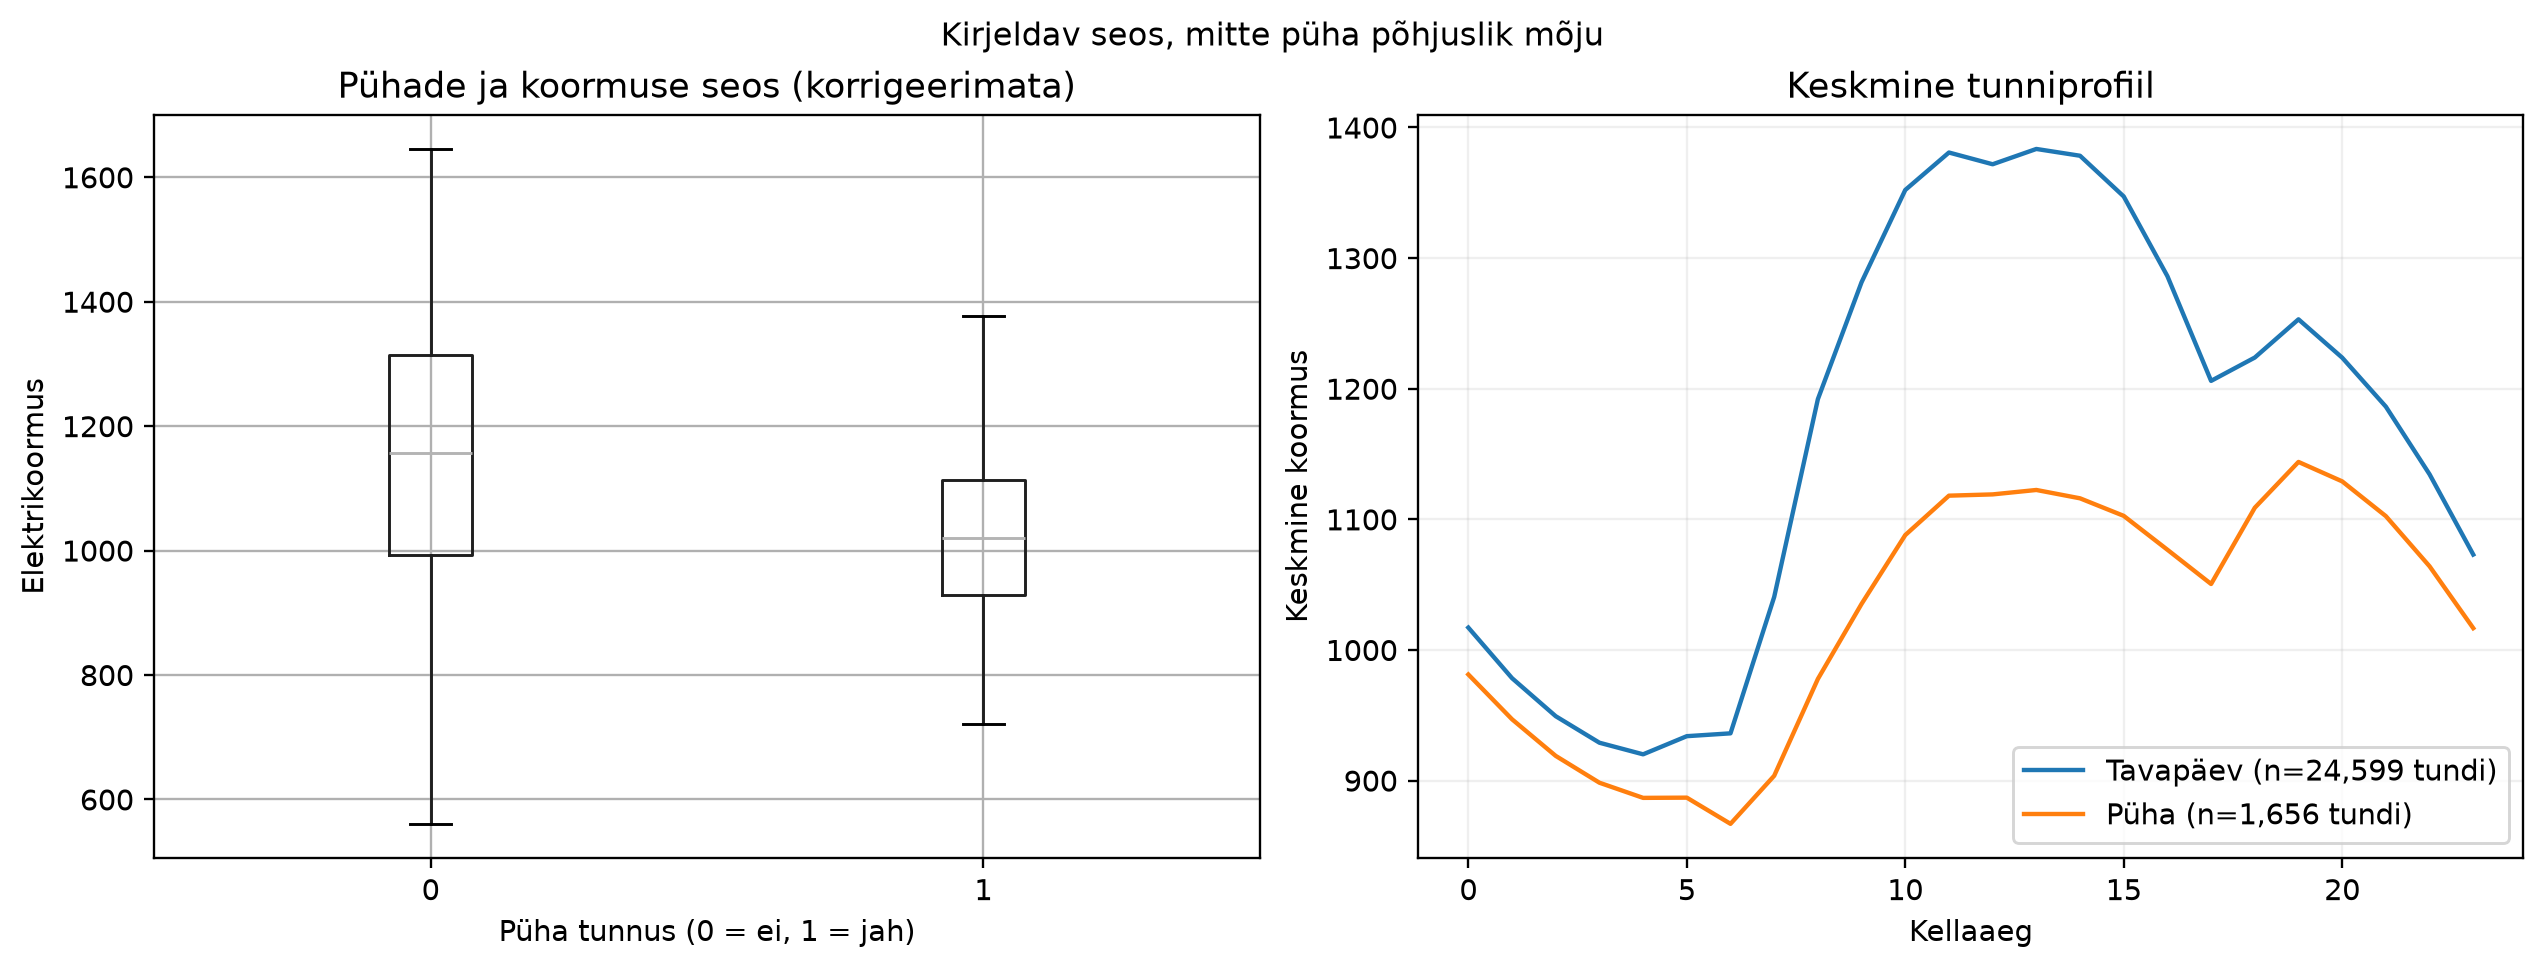

Joonis 6. Võimalikud ebatavalised koormuse muutused


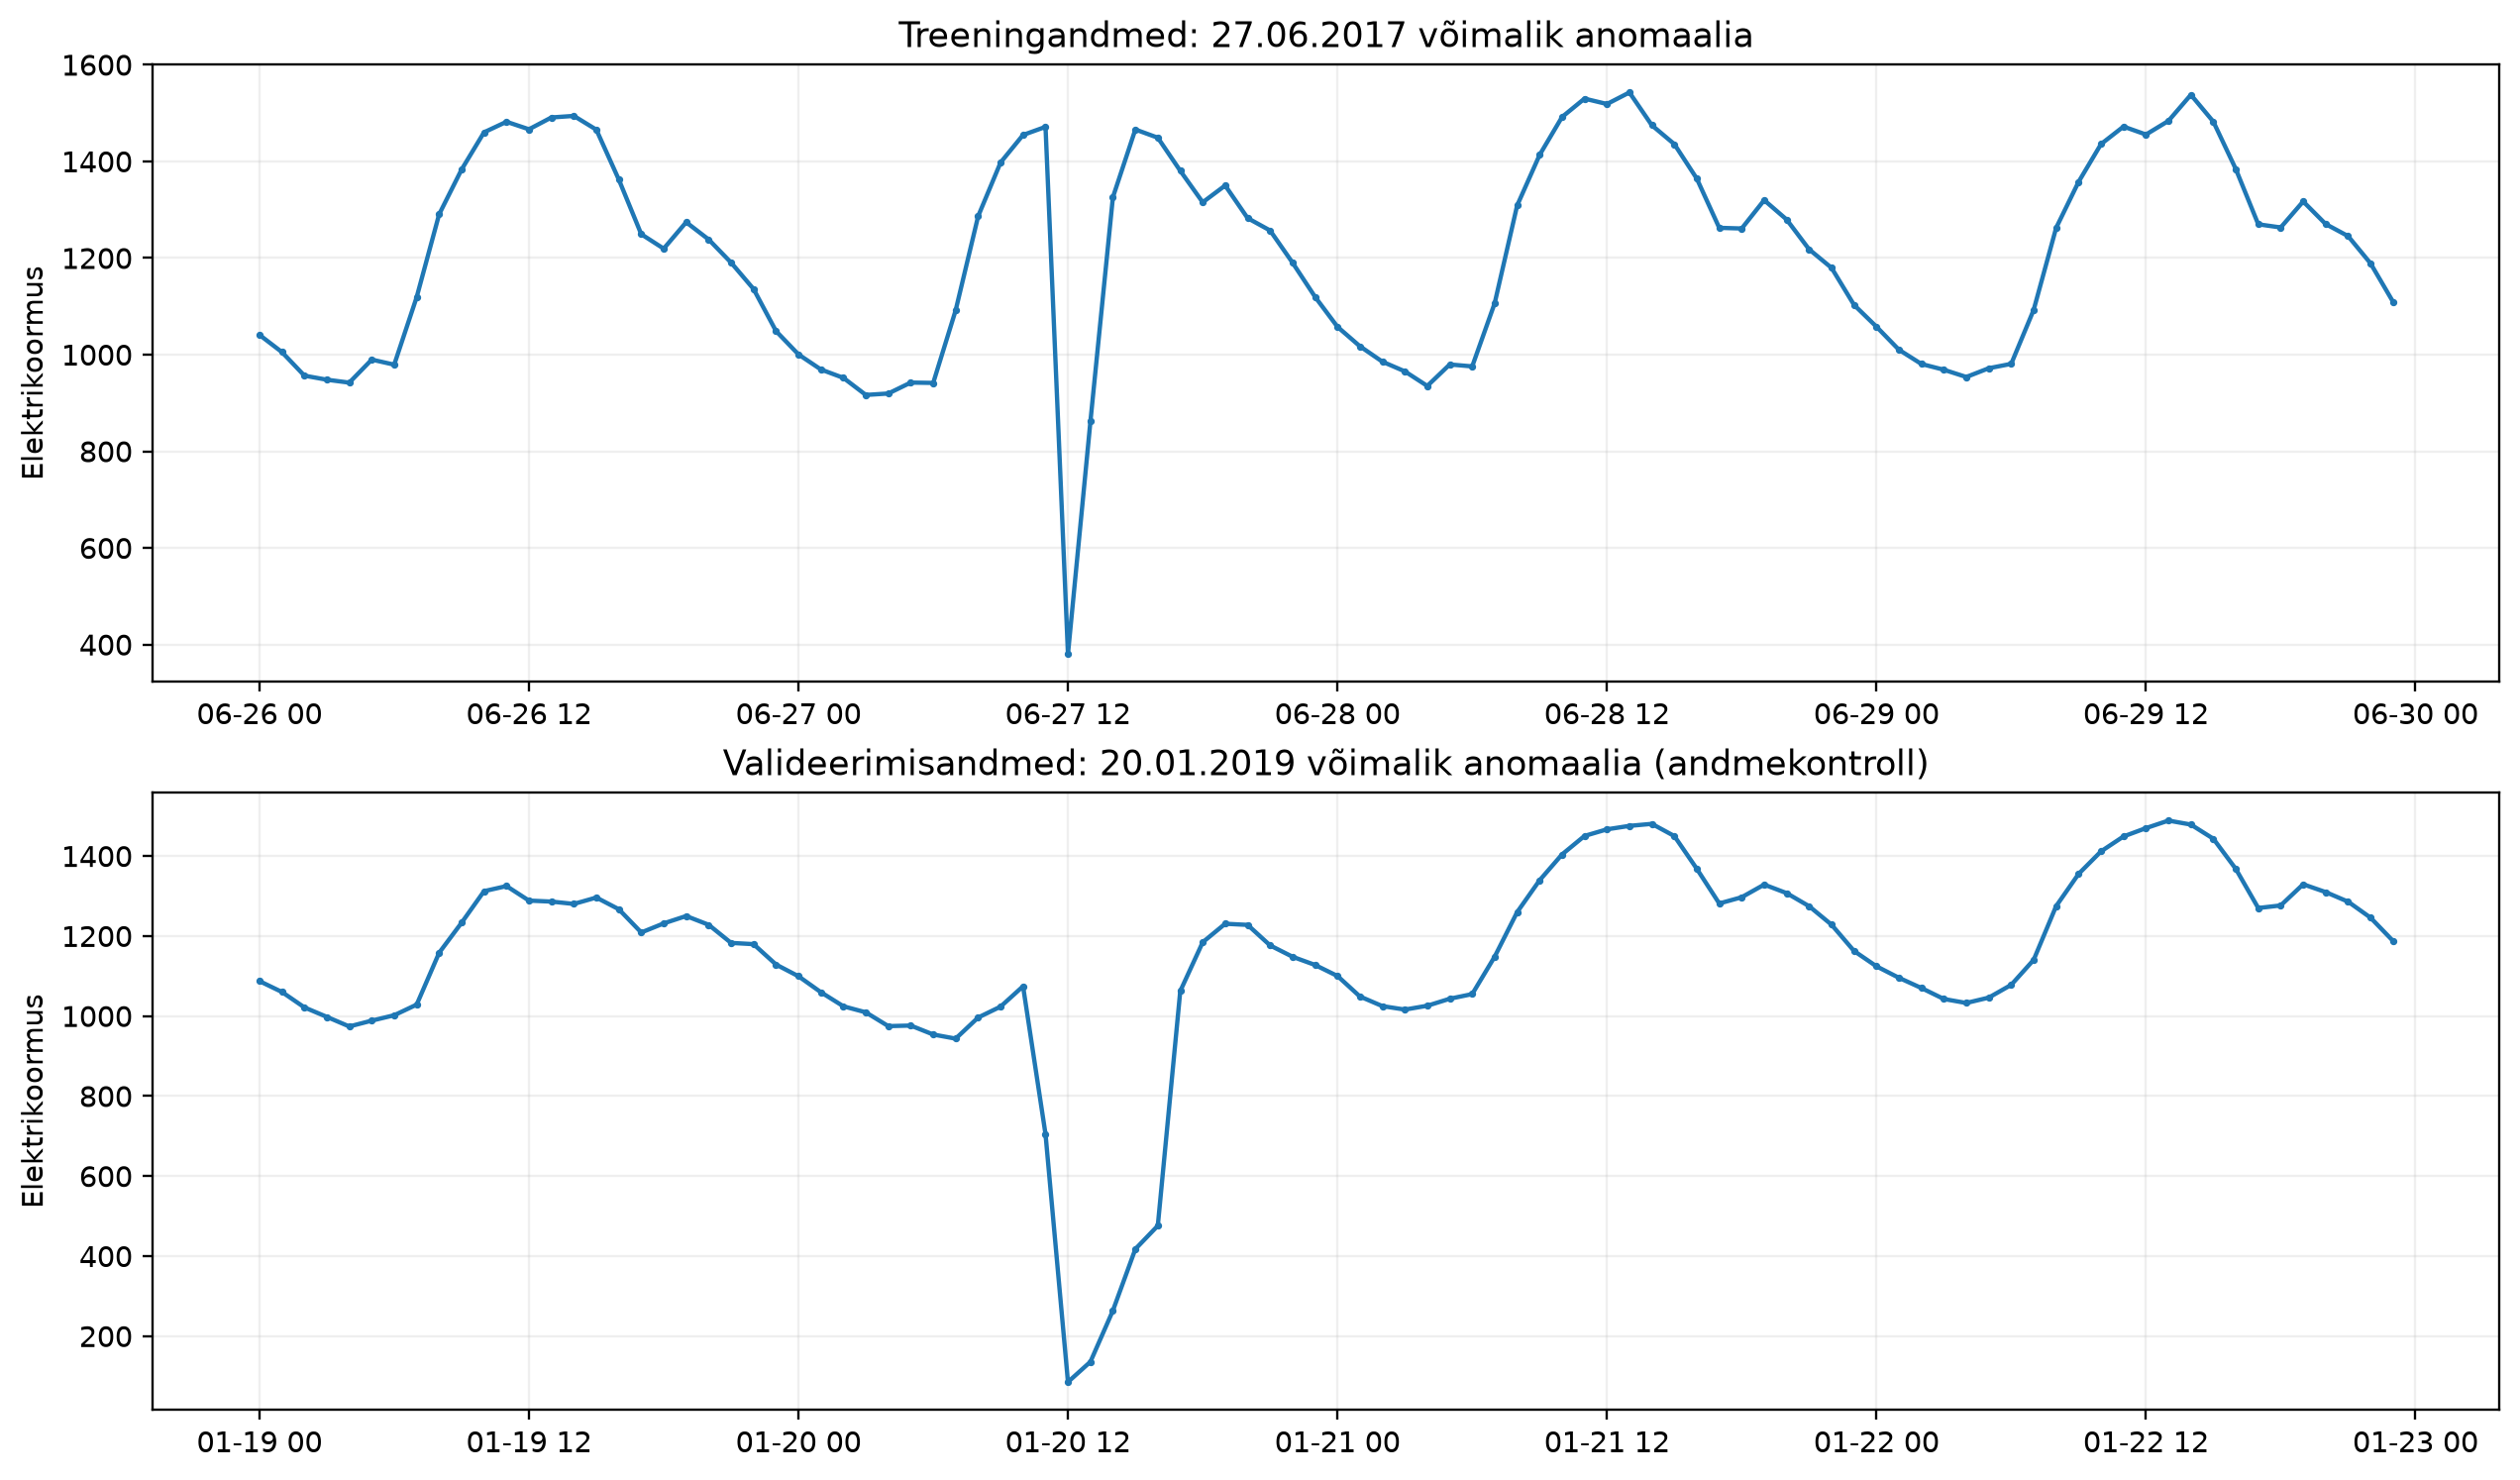

,Tunde,Keskmine koormus,Mediaankoormus
holiday,,,
Tavapäev,24599,1165.78,1156.72
Püha,1656,1027.54,1020.12


Viis suurimat koormuse langust kogu aegreas (andmete kontrolliks):


,Aeg,Koormus,Tunnimuutus
21755,2017-06-27 12:00:00,380.59,-1090.70
21853,2017-07-01 14:00:00,560.70,-782.23
35483,2019-01-20 12:00:00,85.19,-619.45
19410,2017-03-21 19:00:00,711.10,-549.28
520,2015-01-24 17:00:00,509.84,-458.06


In [8]:
show_figure('05_holiday_effect.png', 'Joonis 5. Elektrikoormus pühadel ja tavapäevadel')
show_figure('06_extreme_events.png', 'Joonis 6. Võimalikud ebatavalised koormuse muutused')

holiday_stats = train.groupby('holiday').nat_demand.agg(['count', 'mean', 'median'])
holiday_stats.index = holiday_stats.index.map({0: 'Tavapäev', 1: 'Püha'})
display(holiday_stats.rename(columns={
    'count': 'Tunde', 'mean': 'Keskmine koormus', 'median': 'Mediaankoormus'
}).round(2))

events = data[['datetime', 'nat_demand']].copy()
events['Tunnimuutus'] = events.nat_demand.diff()
print('Viis suurimat koormuse langust kogu aegreas (andmete kontrolliks):')
display(events.nsmallest(5, 'Tunnimuutus').rename(columns={
    'datetime': 'Aeg',
    'nat_demand': 'Koormus'
}).style.format(precision=2))

**Tulemuse tõlgendamine.** Pühade ja tavapäevade keskmiste ning mediaanide võrdlus võimaldab näha nii üldist tasemevahet kui ka seda, kas äärmuslikud koormusväärtused keskmist mõjutavad. Tundide arv näitab ühtlasi võrdlusrühmade suuruse erinevust. Suurima langusega vaatlused on võimalikud kontrollimist vajavad juhtumid, mitte automaatselt mõõtmisvead. Kui erandlikke vaatlusi otsustatakse hiljem muuta või välja jätta, tuleb otsus ja selle mõju prognoositulemustele eraldi põhjendada.

## 8. Järeldused ja seos edasise modelleerimisega

Uuriv analüüs võimaldab kirjeldada **ajast sõltuvaid koormusmustreid**, hinnata **ilmastiku- ja kalendritunnuste seoseid** ning tuvastada **täiendavat kontrolli vajavaid järske muutusi**. Täpsed arvulised tulemused on esitatud iga jooniserühma järel; järeldused tuleb teha nende, mitte üksnes graafikute visuaalse kuju põhjal.

Edasise prognoosimise jaoks on põhjendatud katsetada kellaaja, nädalapäeva ja kuu tunnuseid ning eelneva tunni, ööpäeva ja nädala sama tunni koormust. Temperatuuri ja pühatunnuste kasulikkus on hüpotees, mida tuleb kontrollida mudelite võrdluses. Järske koormuse muutusi tasub käsitleda mudeli vigade analüüsis eraldi, sest keskmine ennustusviga võib varjata nõrgemat toimimist harvaesinevates olukordades.

Analüüsis tuleb järgida ajalist eraldatust: tunnuste valiku ja mudeli treenimise aluseks on treeningandmed, mudelite valiku ja häälestamise aluseks valideerimisandmed ning lõplik erapooletu hindamine tehakse testandmetel. Käesolev notebook ei tõesta veel ühegi tunnuse prognoosilist lisaväärtust ega sisalda mudelite võrdlust.

**Piirangud.** Korrelatsioonid ei tõenda põhjuslikkust; ajatempli ajavöönd ja mõõtühikud tuleb kinnitada andmestiku dokumentatsiooni põhjal; kasutatavad ilmatunnused peavad prognoosimise hetkel olema kättesaadavad. Võimalike anomaaliate põhjuseid ei ole ainult selle analüüsi põhjal võimalik üheselt määrata.